# Motor Imagery BCI: corrected practical notebook

**Manual ambiguity:** its example uses four broadband CSP features while its
table uses six. The primary classifier follows the four-feature example; a
separate descriptive analysis implements mu/4, beta/4, and broadband/6.

Sources: [PhysioNet EEGMMIDB](https://physionet.org/content/eegmmidb/1.0.0/),
[MNE ICA](https://mne.tools/1.11/generated/mne.preprocessing.ICA.html),
[MNE CSP](https://mne.tools/1.11/generated/mne.decoding.CSP.html),
[scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

## 0. Environment

In a fresh Colab/Jupyter runtime, uncomment and run the installation line below,
then restart the kernel if prompted. MNE is pinned to the API used here. The
accompanying requirements file records the exact environment used for validation.

In [1]:
# %pip install mne==1.11.0 numpy==2.3.4 scipy==1.16.3 scikit-learn==1.7.2 matplotlib==3.10.7 threadpoolctl
from pathlib import Path
from collections import deque
from time import perf_counter_ns
import csv
import json
import platform
import importlib.metadata
from importlib.resources import files
import pooch

import numpy as np
import scipy
from scipy.signal import butter, sosfilt, sosfiltfilt, sosfreqz, welch
import matplotlib.pyplot as plt
import mne
from mne.datasets import eegbci
from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.base import clone
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

mne.set_log_level("ERROR")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "results"
FIG = OUT / "figures"
DATA.mkdir(exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
CHANNELS = ["Fp1", "Fp2", "F3", "Fz", "F4", "FC3", "FCz", "FC4",
            "C3", "Cz", "C4", "CP3", "CPz", "CP4", "P3", "P4"]
CAL_RUNS, TRAIN_RUNS, TEST_RUN = [1, 2], [8, 12], 4
EVENT_ID = {"rest": 1, "left": 2, "right": 3}
CLASS_NAMES = ["Left", "Right"]
versions = {name: importlib.metadata.version(name) for name in
            ["mne", "numpy", "scipy", "scikit-learn", "matplotlib", "threadpoolctl"]}
print("Python:", platform.python_version(), "|", platform.platform())
print(json.dumps(versions, indent=2))

def save_figure(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)

def write_csv(name, rows):
    rows = list(rows)
    if rows:
        with (OUT / name).open("w", newline="", encoding="utf-8") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

D:\Github\motor-imagery-bci-signal-processing\.venv-bci\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.14 | Windows-11-10.0.26200-SP0
{
  "mne": "1.11.0",
  "numpy": "2.3.4",
  "scipy": "1.16.3",
  "scikit-learn": "1.7.2",
  "matplotlib": "3.10.7",
  "threadpoolctl": "3.7.0"
}


## 1. Dataset and explicit channel/event mapping

Runs 4, 8 and 12 are left/right **imagery**, not movement execution or fists/feet
imagery. T0 is rest, T1 is left and T2 is right in these runs. Downloads are public
EDF files from PhysioNet's officially linked public AWS mirror, verified against
MNE's SHA-256 registry and cached under `data/`. The global MNE path is not changed.

In [2]:
def load_run(run):
    registry_lines = files("mne").joinpath("data", "eegbci_checksums.txt").read_text().splitlines()
    registry = dict(line.split()[:2] for line in registry_lines if line.strip() and not line.startswith("#"))
    name = f"S001/S001R{run:02d}.edf"
    digest = registry[name].removeprefix("sha256:")
    path = pooch.retrieve(
        url="https://physionet-open.s3.amazonaws.com/eegmmidb/1.0.0/" + name,
        known_hash="sha256:" + digest, fname=Path(name).name,
        path=DATA / "MNE-eegbci-data" / "files" / "eegmmidb" / "1.0.0" / "S001",
        downloader=pooch.HTTPDownloader(timeout=45, chunk_size=65536))
    raw = mne.io.read_raw_edf(path, preload=True, verbose="ERROR")
    eegbci.standardize(raw)
    missing = sorted(set(CHANNELS) - set(raw.ch_names))
    if missing:
        raise ValueError(f"Missing required channels: {missing}")
    raw.pick(CHANNELS).reorder_channels(CHANNELS)
    raw.set_montage("standard_1020", on_missing="raise")
    assert raw.ch_names == CHANNELS and raw.info["sfreq"] == 160.0
    return raw

raws = {run: load_run(run) for run in CAL_RUNS + TRAIN_RUNS + [TEST_RUN]}
SFREQ = float(raws[TRAIN_RUNS[0]].info["sfreq"])
INFO = raws[TRAIN_RUNS[0]].info.copy()
print(f"Selected {len(CHANNELS)} channels at {SFREQ:g} Hz:", CHANNELS)
for run, raw in raws.items():
    print(f"Run {run:02}: {raw.n_times} samples; annotations:",
          dict(zip(*np.unique(raw.annotations.description, return_counts=True))))

Selected 16 channels at 160 Hz: ['Fp1', 'Fp2', 'F3', 'Fz', 'F4', 'FC3', 'FCz', 'FC4', 'C3', 'Cz', 'C4', 'CP3', 'CPz', 'CP4', 'P3', 'P4']
Run 01: 9760 samples; annotations: {np.str_('T0'): np.int64(1)}
Run 02: 9760 samples; annotations: {np.str_('T0'): np.int64(1)}
Run 08: 20000 samples; annotations: {np.str_('T0'): np.int64(15), np.str_('T1'): np.int64(8), np.str_('T2'): np.int64(7)}
Run 12: 20000 samples; annotations: {np.str_('T0'): np.int64(15), np.str_('T1'): np.int64(7), np.str_('T2'): np.int64(8)}
Run 04: 20000 samples; annotations: {np.str_('T0'): np.int64(15), np.str_('T1'): np.int64(8), np.str_('T2'): np.int64(7)}


## 2. Task 1: independent ICA calibration and causal bandpass

ICA is fitted on independent baseline recordings filtered to **1-40 Hz**, retaining
blink frequencies that an 8 Hz high-pass would remove. We correlate components
with **both** Fp1 and Fp2 using a fixed absolute threshold of 0.5. These EEG channels
are ocular proxies, not dedicated EOG measurements: the maps, scores, time courses,
and before/after plots must support an ocular interpretation. We never force an
exclusion merely to obtain a larger attenuation number or higher classifier score.

Classification uses a fourth-order Butterworth **prototype**, 8-30 Hz, represented
by second-order sections. The bandpass transformation has eight digital poles.
Forward-only filtering preserves state and uses no future samples. The same filter
and initial state are used for offline training and online inference. The extra
1-40 Hz zero-phase filter below is only for offline ICA calibration/diagnostics.

ICA iterations: 27
Candidate ocular components excluded (zero-based): [1]


{'component': 0, 'Fp1_r': 0.4210828224256443, 'Fp2_r': 0.4396190393862926, 'excluded': False}
{'component': 1, 'Fp1_r': 0.8762406494818243, 'Fp2_r': 0.8828107903995142, 'excluded': True}
{'component': 2, 'Fp1_r': 0.14941492270070106, 'Fp2_r': 0.20240410494731537, 'excluded': False}
{'component': 3, 'Fp1_r': 0.02815493784713638, 'Fp2_r': 0.04085062940660429, 'excluded': False}
{'component': 4, 'Fp1_r': 0.08092823589836823, 'Fp2_r': 0.06348993293161963, 'excluded': False}
{'component': 5, 'Fp1_r': 0.09603813103480258, 'Fp2_r': 0.06335846308955137, 'excluded': False}
{'component': 6, 'Fp1_r': -0.10525189652531172, 'Fp2_r': -0.08275164007905489, 'excluded': False}
{'component': 7, 'Fp1_r': 0.04155305650772554, 'Fp2_r': 0.05018505812797851, 'excluded': False}
{'component': 8, 'Fp1_r': 0.13741173954585345, 'Fp2_r': -0.03528398695962926, 'excluded': False}
{'component': 9, 'Fp1_r': -0.12573854057814426, 'Fp2_r': -0.06567369597532718, 'excluded': False}
{'component': 10, 'Fp1_r': 0.07166849648

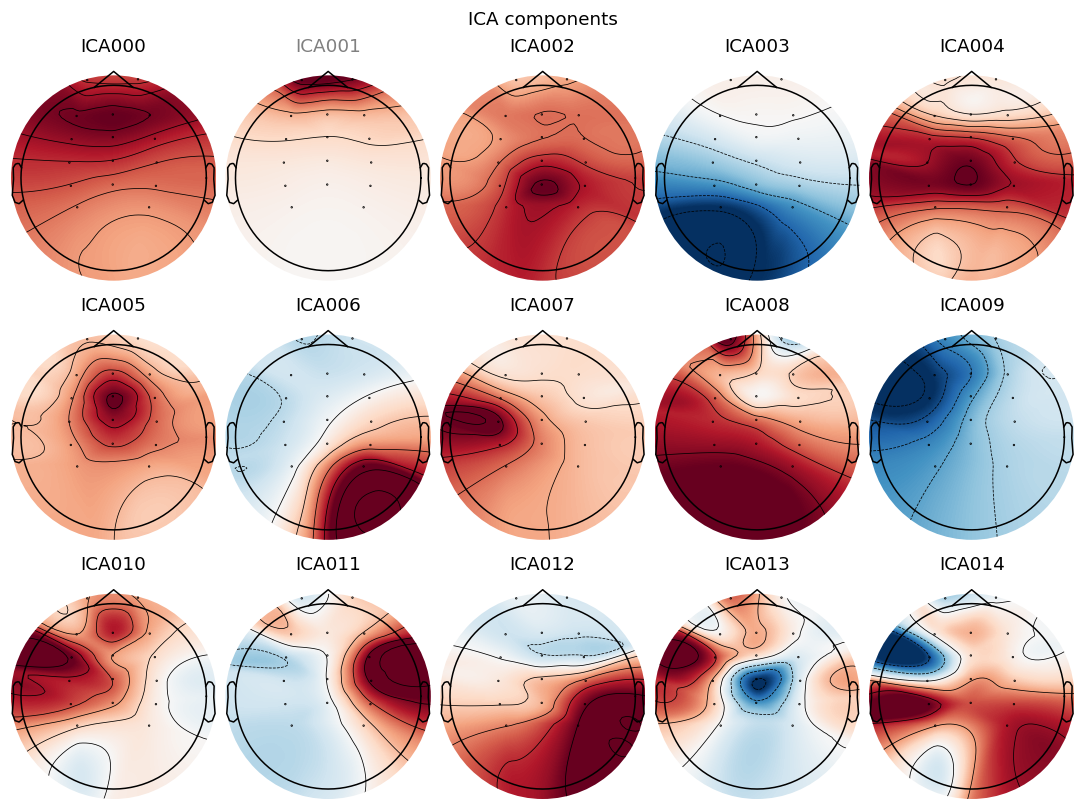

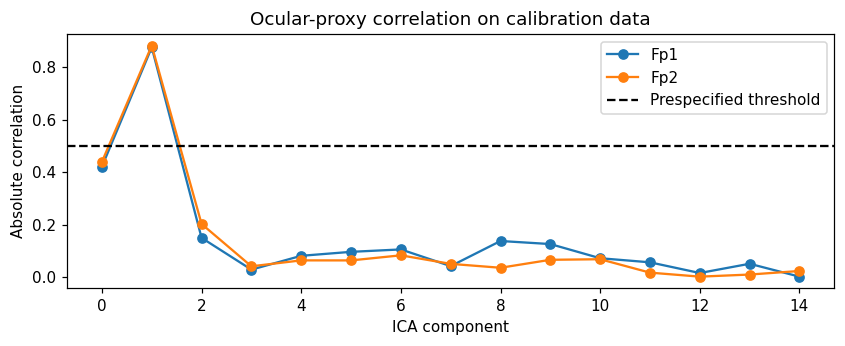

In [3]:
calibration_parts = [raws[r].copy().filter(1.0, 40.0, method="iir",
                      iir_params={"order": 4, "ftype": "butter"}, verbose="ERROR") for r in CAL_RUNS]
calibration = mne.concatenate_raws(calibration_parts)
ica = mne.preprocessing.ICA(n_components=15, method="fastica", random_state=SEED,
                            max_iter=2000)
with threadpool_limits(limits=1):
    ica.fit(calibration, verbose="ERROR")
eog_scores = {}
candidates = set()
for frontal in ["Fp1", "Fp2"]:
    indices, scores = ica.find_bads_eog(calibration, ch_name=frontal,
                                       threshold=0.5, measure="correlation", verbose="ERROR")
    candidates.update(indices)
    eog_scores[frontal] = np.asarray(scores)
ica.exclude = sorted(int(component) for component in candidates)
print("ICA iterations:", ica.n_iter_)
print("Candidate ocular components excluded (zero-based):", ica.exclude)
if not ica.exclude:
    print("No component met the prespecified rule; artifact removal is NOT demonstrated.")
score_rows = [{"component": i, "Fp1_r": float(eog_scores["Fp1"][i]),
               "Fp2_r": float(eog_scores["Fp2"][i]), "excluded": i in ica.exclude}
              for i in range(ica.n_components_)]
write_csv("ica_scores.csv", score_rows)
for row in score_rows:
    print(row)

figs = ica.plot_components(picks=list(range(ica.n_components_)), show=False)
for i, fig in enumerate(figs if isinstance(figs, list) else [figs]):
    save_figure(fig, f"ica_components_{i}")
fig, ax = plt.subplots(figsize=(9, 3))
for channel, scores in eog_scores.items():
    ax.plot(np.abs(scores), "o-", label=channel)
ax.axhline(0.5, color="black", linestyle="--", label="Prespecified threshold")
ax.set(xlabel="ICA component", ylabel="Absolute correlation", title="Ocular-proxy correlation on calibration data")
ax.legend()
save_figure(fig, "ica_correlations")

### Artifact evidence and limits of the SNR requirement

The dataset has neither a clean EEG reference nor a dedicated EOG channel. Thus
true SNR improvement is **not identifiable** here. We report a clearly labelled
proxy: attenuation of 1-4 Hz power at Fp1/Fp2, before versus after ICA on calibration
data. Low-frequency neural activity also contributes, so this is not proof of
blink-specific suppression or of the rubric's >12 dB true-SNR target. An unchanged
signal gives 0 dB. A negative value is retained rather than hidden.

Fp1: 1-4 Hz attenuation proxy = 7.79 dB (not true SNR improvement)
Fp2: 1-4 Hz attenuation proxy = 8.10 dB (not true SNR improvement)


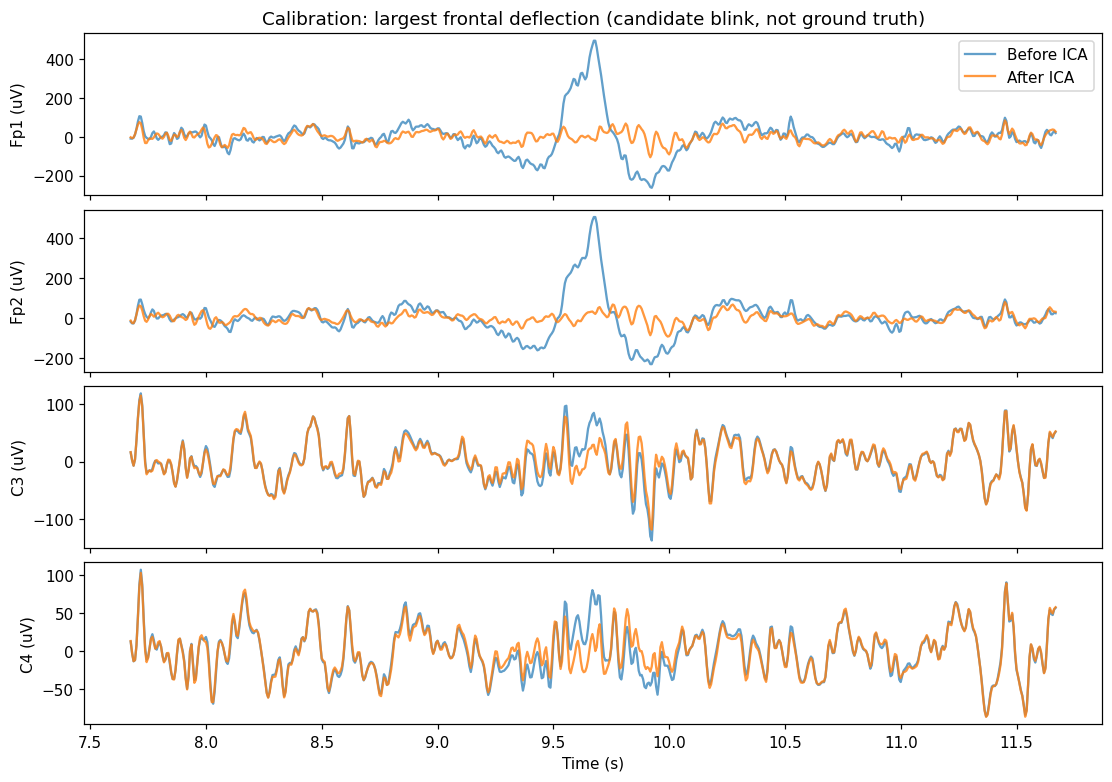

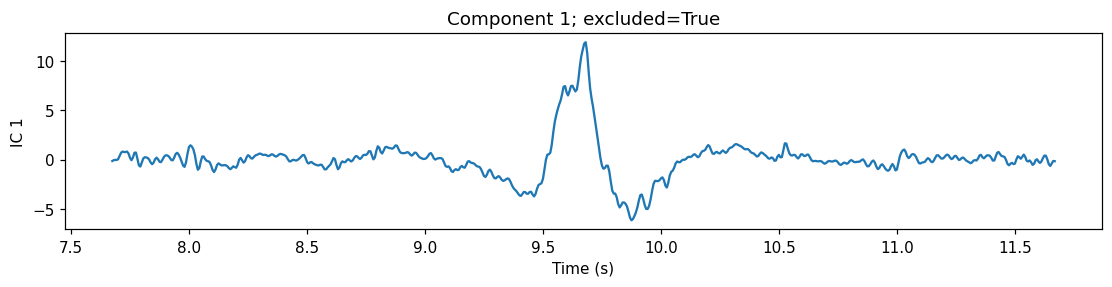

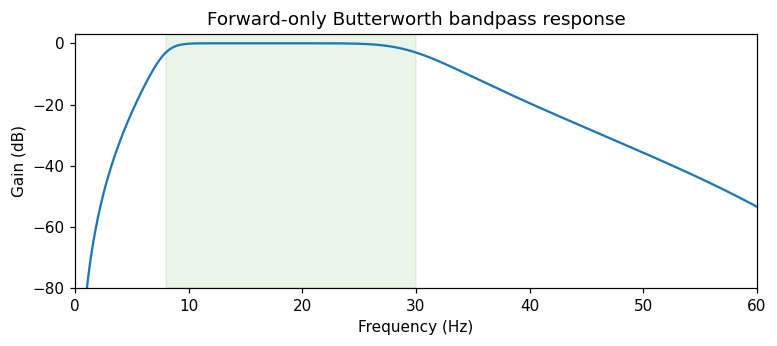

In [4]:
calibration_clean = ica.apply(calibration.copy(), verbose="ERROR")
cal_before = calibration.get_data()
cal_after = calibration_clean.get_data()
fp = [CHANNELS.index(ch) for ch in ["Fp1", "Fp2"]]
freq, before_psd = welch(cal_before[fp], fs=SFREQ, window="hamming", nperseg=160, noverlap=80)
_, after_psd = welch(cal_after[fp], fs=SFREQ, window="hamming", nperseg=160, noverlap=80)
blink_band = (freq >= 1) & (freq <= 4)
before_power = np.trapezoid(before_psd[:, blink_band], freq[blink_band], axis=-1)
after_power = np.trapezoid(after_psd[:, blink_band], freq[blink_band], axis=-1)
attenuation_db = 10 * np.log10(before_power / np.maximum(after_power, np.finfo(float).tiny))
for channel, value in zip(["Fp1", "Fp2"], attenuation_db):
    print(f"{channel}: 1-4 Hz attenuation proxy = {value:.2f} dB (not true SNR improvement)")

# Show the largest frontal deflection away from recording edges/boundaries.
proxy = np.abs(cal_before[fp].mean(axis=0))
eligible = np.ones(proxy.size, dtype=bool)
eligible[:int(3 * SFREQ)] = False
eligible[-int(3 * SFREQ):] = False
boundary = raws[CAL_RUNS[0]].n_times
eligible[max(0, boundary-480):boundary+480] = False
peak = np.argmax(np.where(eligible, proxy, -np.inf))
left, right = max(0, peak-320), min(proxy.size, peak+320)
time_axis = np.arange(left, right) / SFREQ
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True, layout="constrained")
for ax, channel in zip(axes, ["Fp1", "Fp2", "C3", "C4"]):
    j = CHANNELS.index(channel)
    ax.plot(time_axis, cal_before[j, left:right] * 1e6, label="Before ICA", alpha=0.7)
    ax.plot(time_axis, cal_after[j, left:right] * 1e6, label="After ICA", alpha=0.8)
    ax.set(ylabel=f"{channel} (uV)")
axes[0].legend(loc="upper right")
axes[0].set_title("Calibration: largest frontal deflection (candidate blink, not ground truth)")
axes[-1].set_xlabel("Time (s)")
save_figure(fig, "ica_before_after")

sources = ica.get_sources(calibration).get_data()
shown = ica.exclude or [int(np.argmax(np.abs(eog_scores["Fp1"])))]
fig, axes = plt.subplots(len(shown), 1, figsize=(10, max(2.5, 2*len(shown))), squeeze=False,
                         sharex=True, layout="constrained")
for ax, component in zip(axes[:, 0], shown):
    ax.plot(time_axis, sources[component, left:right])
    ax.set(ylabel=f"IC {component}", title=f"Component {component}; excluded={component in ica.exclude}")
axes[-1, 0].set_xlabel("Time (s)")
save_figure(fig, "ica_candidate_timecourses")

# Build the exact affine mapping implemented by MNE's fitted ICA reconstruction.
# The mapping is fixed by independent calibration; it is never fitted to test data.
probe = np.column_stack([np.zeros(len(CHANNELS)), np.eye(len(CHANNELS))]) * 1e-6
probe_raw = mne.io.RawArray(probe, INFO.copy(), verbose="ERROR")
probe_clean = ica.apply(probe_raw, verbose="ERROR").get_data()
ICA_OFFSET = probe_clean[:, :1]
ICA_MATRIX = (probe_clean[:, 1:] - ICA_OFFSET) / 1e-6
np.testing.assert_allclose(ICA_MATRIX @ cal_before + ICA_OFFSET, cal_after, atol=1e-14, rtol=1e-8)

SOS = butter(4, [8, 30], btype="bandpass", fs=SFREQ, output="sos")
def causal_preprocess(raw, sos=SOS):
    filtered = sosfilt(sos, raw.get_data(), axis=-1)
    return ICA_MATRIX @ filtered + ICA_OFFSET

clean = {run: causal_preprocess(raws[run]) for run in TRAIN_RUNS}
filtered_only = {run: sosfilt(SOS, raws[run].get_data(), axis=-1) for run in TRAIN_RUNS}
f_response, h_response = sosfreqz(SOS, worN=2048, fs=SFREQ)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(f_response, 20*np.log10(np.maximum(np.abs(h_response), 1e-8)))
ax.axvspan(8, 30, color="tab:green", alpha=0.1)
ax.set(xlim=(0, 60), ylim=(-80, 3), xlabel="Frequency (Hz)", ylabel="Gain (dB)",
       title="Forward-only Butterworth bandpass response")
save_figure(fig, "filter_response")

### Four-second epochs and trial counts

MNE includes both interval endpoints: `tmin=0, tmax=4` at 160 Hz gives 641 samples.
This matches the manual. Rest is excluded from the two-class classifier. No
amplitude-based trial rejection is silently applied; retained/dropped counts are
printed. Four-second trial windows and 500 ms streaming windows are kept distinct.

Run 8: retained 15 imagery trials; dropped epochs: 0
Run 12: retained 15 imagery trials; dropped epochs: 0
Training/validation shape: (30, 16, 641) | left/right: [15 15]


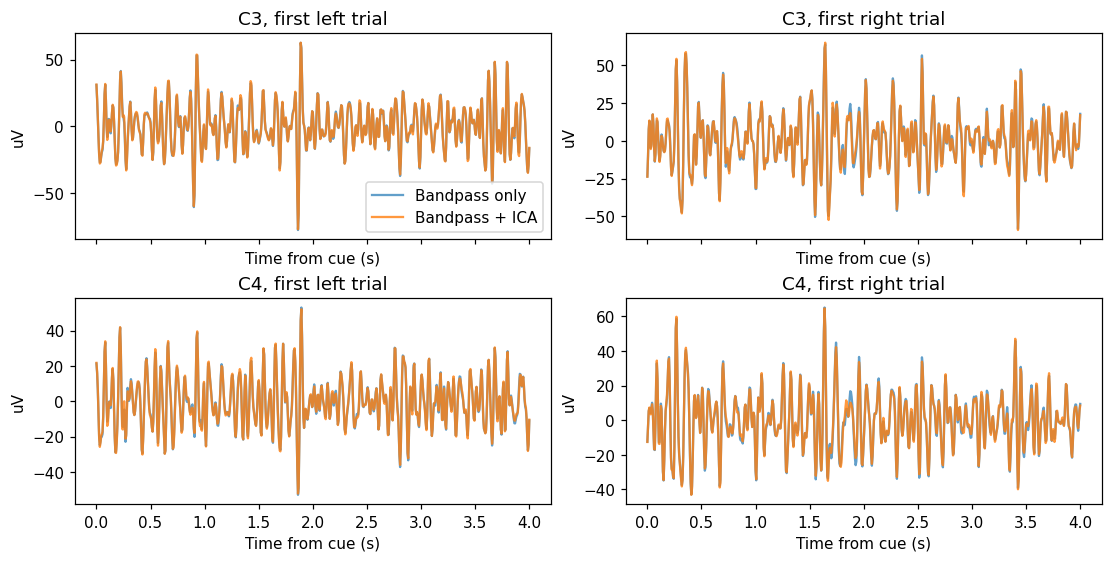

In [5]:
def make_epochs(run, data):
    processed = mne.io.RawArray(data, raws[run].info.copy(), verbose="ERROR")
    processed.set_annotations(raws[run].annotations.copy())
    events, _ = mne.events_from_annotations(processed,
                 event_id={"T0": 1, "T1": 2, "T2": 3}, verbose="ERROR")
    return mne.Epochs(processed, events, event_id=EVENT_ID, tmin=0, tmax=4,
                      baseline=None, preload=True, reject_by_annotation=True, verbose="ERROR")

epochs_by_run = {r: make_epochs(r, clean[r]) for r in TRAIN_RUNS}
X_parts, y_parts, run_groups, trial_rows = [], [], [], []
for run, epochs in epochs_by_run.items():
    mi = epochs[["left", "right"]]
    X_parts.append(mi.get_data(copy=True))
    y_parts.append(mi.events[:, 2] - 2)
    run_groups.extend([run] * len(mi))
    for event in mi.events:
        trial_rows.append({"run": run, "sample": int(event[0]), "label": int(event[2]-2)})
    print(f"Run {run}: retained {len(mi)} imagery trials; dropped epochs:",
          sum(bool(reason) for reason in epochs.drop_log))
X = np.concatenate(X_parts)
y = np.concatenate(y_parts).astype(int)
run_groups = np.asarray(run_groups)
assert X.shape[1:] == (16, 641)
assert np.bincount(y).min() >= 10, "Need at least ten trials per class for ten-fold CV."
print("Training/validation shape:", X.shape, "| left/right:", np.bincount(y))
write_csv("training_trials.csv", trial_rows)

example_run = TRAIN_RUNS[0]
before_epochs = make_epochs(example_run, filtered_only[example_run])
after_epochs = epochs_by_run[example_run]
fig, axes = plt.subplots(2, 2, figsize=(10, 5), sharex=True, layout="constrained")
for row, channel in enumerate(["C3", "C4"]):
    for col, label in enumerate(["left", "right"]):
        j = CHANNELS.index(channel)
        axes[row, col].plot(after_epochs.times, before_epochs[label].get_data()[0, j]*1e6,
                           label="Bandpass only", alpha=0.7)
        axes[row, col].plot(after_epochs.times, after_epochs[label].get_data()[0, j]*1e6,
                           label="Bandpass + ICA", alpha=0.8)
        axes[row, col].set(title=f"{channel}, first {label} trial", ylabel="uV", xlabel="Time from cue (s)")
axes[0, 0].legend()
save_figure(fig, "cleaned_epochs")

## 3. Task 2: CSP log-variance and spectral evidence

Centering each trial/window before CSP makes MNE's log-average-power transform
equal to `log(var(W @ X))` (population variance). `component_order='alternate'`
chooses largest, smallest, second-largest, second-smallest generalized eigenvalues.
Thus `[0, 2, 3, 1]` displays the first two and last two in descending eigenvalue
order. Using the last two array rows with MNE's default mutual-information ordering
would not select the intended extremes.

All plots in this section are descriptive fits on the training recordings only;
these fitted objects are not reused for cross-validation. We do not select a band
or component count after seeing these plots or the held-out run's performance.

CSP feature shape: (30, 4) | exact log-variance check passed


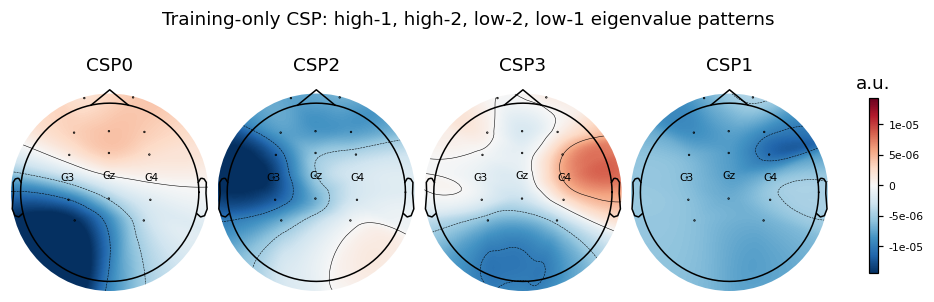

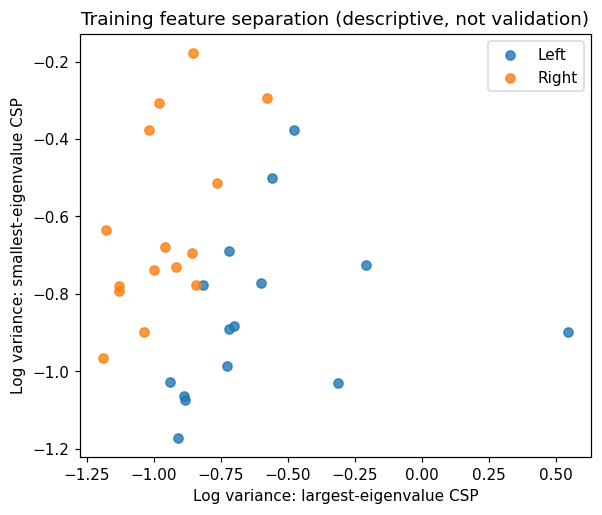

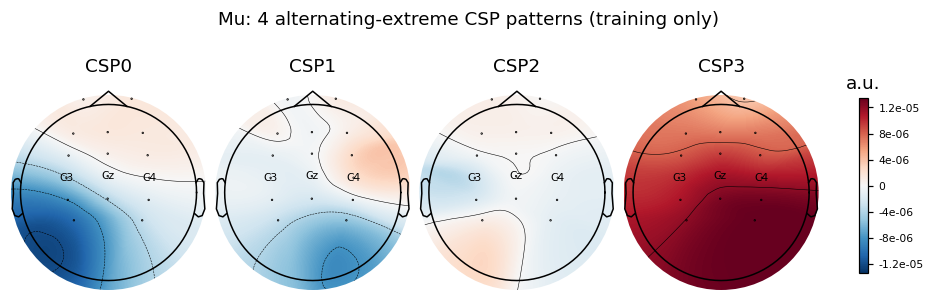

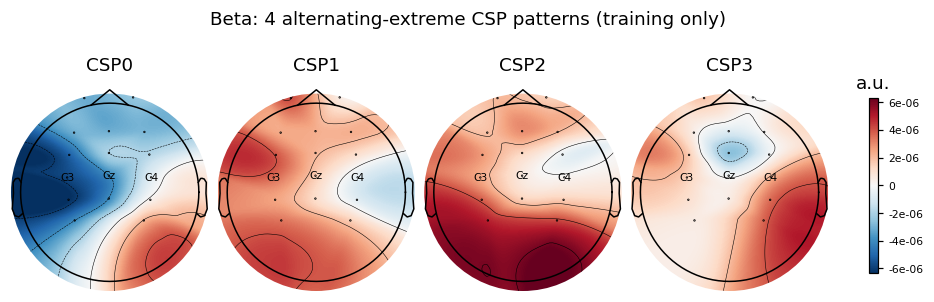

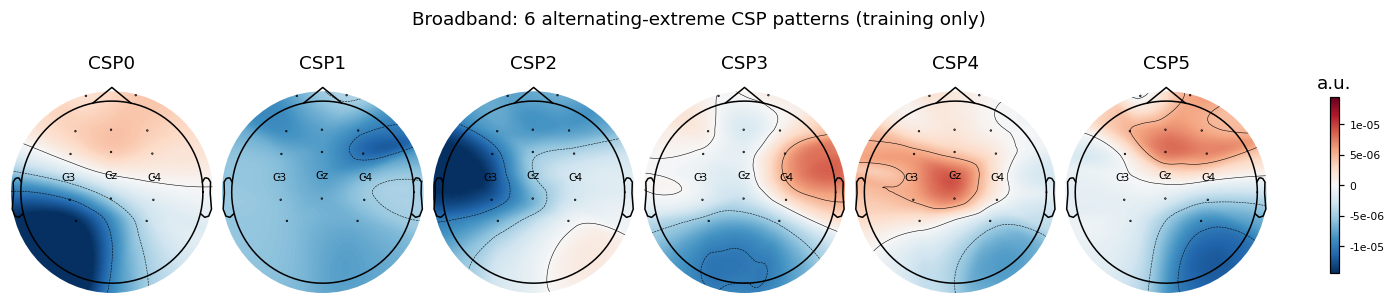

{'band': 'Mu', 'components': 4, 'features': '(30, 4)', 'empirical_normalized_variance_ratio': 1.5978285422710405, 'manual_target': 3.2}
{'band': 'Beta', 'components': 4, 'features': '(30, 4)', 'empirical_normalized_variance_ratio': 1.3886297569666493, 'manual_target': 2.8}
{'band': 'Broadband', 'components': 6, 'features': '(30, 6)', 'empirical_normalized_variance_ratio': 1.3795980390969216, 'manual_target': 4.1}
Ratios use empirical projected power, not exact regularized solver eigenvalues; targets are not guaranteed.


In [6]:
def center_trials(data):
    return data - data.mean(axis=-1, keepdims=True)

def make_pipeline(kind="lda", n_components=4):
    csp = CSP(n_components=n_components, log=True, norm_trace=False,
              reg="ledoit_wolf", component_order="alternate")
    classifier = (LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
                  if kind == "lda" else SVC(kernel="rbf", probability=True, random_state=SEED))
    return Pipeline([("center", FunctionTransformer(center_trials)), ("csp", csp),
                     ("scale", StandardScaler()), ("classifier", classifier)])

descriptive_csp = make_pipeline().named_steps["csp"]
with threadpool_limits(limits=1):
    features = descriptive_csp.fit_transform(center_trials(X), y)
projected = np.einsum("kc,nct->nkt", descriptive_csp.filters_[:4], center_trials(X))
np.testing.assert_allclose(features, np.log(np.var(projected, axis=-1)), rtol=1e-7, atol=1e-7)
print("CSP feature shape:", features.shape, "| exact log-variance check passed")

fig = descriptive_csp.plot_patterns(INFO, components=[0, 2, 3, 1], ch_type="eeg",
                                    units="a.u.", scalings=1, cbar_fmt="%.2g", size=1.4,
                                    show_names=lambda ch: ch if ch in ["C3", "Cz", "C4"] else "",
                                    show=False)
fig.suptitle("Training-only CSP: high-1, high-2, low-2, low-1 eigenvalue patterns", y=1.08)
save_figure(fig, "csp_patterns")
fig, ax = plt.subplots(figsize=(6, 5))
for label, name in enumerate(CLASS_NAMES):
    ax.scatter(features[y == label, 0], features[y == label, 1], label=name, alpha=0.8)
ax.set(xlabel="Log variance: largest-eigenvalue CSP", ylabel="Log variance: smallest-eigenvalue CSP",
       title="Training feature separation (descriptive, not validation)")
ax.legend()
save_figure(fig, "csp_feature_scatter")

band_rows = []
for name, limits, count, target in [("Mu", (8, 12), 4, 3.2), ("Beta", (16, 24), 4, 2.8),
                                   ("Broadband", (8, 30), 6, 4.1)]:
    sos = butter(4, limits, btype="bandpass", fs=SFREQ, output="sos")
    band_x = np.concatenate([make_epochs(r, causal_preprocess(raws[r], sos))[["left", "right"]].get_data()
                             for r in TRAIN_RUNS])
    band_csp = make_pipeline(n_components=count).named_steps["csp"]
    with threadpool_limits(limits=1):
        band_features = band_csp.fit_transform(center_trials(band_x), y)
    power0 = np.exp(band_features[y == 0]).mean(axis=0)
    power1 = np.exp(band_features[y == 1]).mean(axis=0)
    empirical_lambda = power0 / (power0 + power1)
    ratio = float(empirical_lambda.max() / empirical_lambda.min())
    band_rows.append({"band": name, "components": count, "features": str(band_features.shape),
                      "empirical_normalized_variance_ratio": ratio, "manual_target": target})
    fig = band_csp.plot_patterns(INFO, components=list(range(count)), ch_type="eeg",
                                units="a.u.", scalings=1, cbar_fmt="%.2g", size=1.4,
                                show_names=lambda ch: ch if ch in ["C3", "Cz", "C4"] else "",
                                show=False)
    fig.suptitle(f"{name}: {count} alternating-extreme CSP patterns (training only)", y=1.08)
    save_figure(fig, f"csp_{name.lower()}")
write_csv("band_comparison.csv", band_rows)
for row in band_rows:
    print(row)
print("Ratios use empirical projected power, not exact regularized solver eigenvalues; targets are not guaranteed.")

### Welch PSD and paired rest-versus-imagery ERD

PSD uses 160-sample (1 second) Hamming windows, 80-sample overlap and 160-point FFT.
For each training imagery trial, its immediately preceding T0 segment provides a
**paired** four-second rest reference. We verify the reference falls inside T0.
Alpha ERD is `100 * (rest_power - imagery_power) / rest_power`, using 8-12 Hz power:
positive means desynchronization, negative means synchronization. This is a band
power comparison, not a claim of event-related changes based only on peak height.

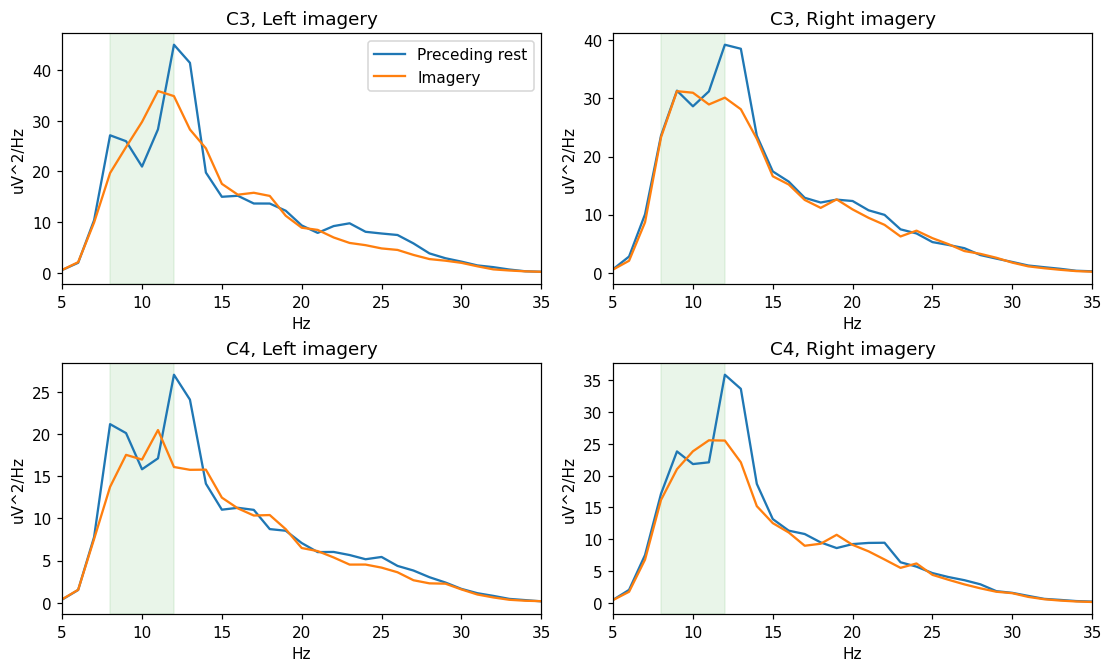

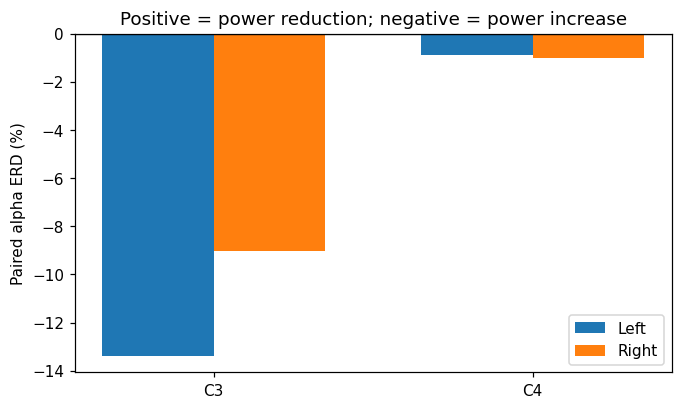

{'channel': 'C3', 'class': 'Left', 'paired_trials': 15, 'mean_alpha_ERD_percent': -13.391319025269388}
{'channel': 'C3', 'class': 'Right', 'paired_trials': 15, 'mean_alpha_ERD_percent': -9.016193967393258}
{'channel': 'C4', 'class': 'Left', 'paired_trials': 15, 'mean_alpha_ERD_percent': -0.8948698539344501}
{'channel': 'C4', 'class': 'Right', 'paired_trials': 15, 'mean_alpha_ERD_percent': -1.0254212200388617}


In [7]:
rest_trials, imagery_trials, pair_labels = [], [], []
for run in TRAIN_RUNS:
    raw = raws[run]
    annotations = list(zip(raw.annotations.onset, raw.annotations.duration, raw.annotations.description))
    for idx, (onset, duration, description) in enumerate(annotations):
        if description not in ["T1", "T2"] or idx == 0:
            continue
        previous_onset, previous_duration, previous_description = annotations[idx - 1]
        onset_sample = int(round(onset * SFREQ))
        n = int(4 * SFREQ)
        rest_start = onset_sample - n
        if (previous_description == "T0" and rest_start >= round(previous_onset * SFREQ)
                and previous_onset + previous_duration >= onset - 1/SFREQ
                and duration >= 4 and onset_sample + n <= raw.n_times):
            rest_trials.append(clean[run][:, rest_start:onset_sample])
            imagery_trials.append(clean[run][:, onset_sample:onset_sample+n])
            pair_labels.append(0 if description == "T1" else 1)
rest_trials, imagery_trials = np.array(rest_trials), np.array(imagery_trials)
pair_labels = np.array(pair_labels)
assert len(pair_labels) > 0
freqs, psd_rest = welch(rest_trials, fs=SFREQ, window="hamming", nperseg=160, noverlap=80, nfft=160, axis=-1)
_, psd_mi = welch(imagery_trials, fs=SFREQ, window="hamming", nperseg=160, noverlap=80, nfft=160, axis=-1)
alpha = (freqs >= 8) & (freqs <= 12)
rest_alpha = np.trapezoid(psd_rest[..., alpha], freqs[alpha], axis=-1)
mi_alpha = np.trapezoid(psd_mi[..., alpha], freqs[alpha], axis=-1)
erd = 100 * (rest_alpha-mi_alpha) / np.maximum(rest_alpha, np.finfo(float).tiny)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
erd_rows = []
for row, channel in enumerate(["C3", "C4"]):
    j = CHANNELS.index(channel)
    for label, name in enumerate(CLASS_NAMES):
        mask = pair_labels == label
        axes[row, label].plot(freqs, psd_rest[mask, j].mean(axis=0)*1e12, label="Preceding rest")
        axes[row, label].plot(freqs, psd_mi[mask, j].mean(axis=0)*1e12, label="Imagery")
        axes[row, label].axvspan(8, 12, alpha=0.1, color="tab:green")
        axes[row, label].set(xlim=(5, 35), xlabel="Hz", ylabel="uV^2/Hz", title=f"{channel}, {name} imagery")
        erd_rows.append({"channel": channel, "class": name, "paired_trials": int(mask.sum()),
                         "mean_alpha_ERD_percent": float(erd[mask, j].mean())})
axes[0, 0].legend()
save_figure(fig, "welch_psd")
write_csv("alpha_erd.csv", erd_rows)
fig, ax = plt.subplots(figsize=(7, 4))
for label, name in enumerate(CLASS_NAMES):
    values = [erd[pair_labels == label, CHANNELS.index(ch)].mean() for ch in ["C3", "C4"]]
    ax.bar(np.arange(2) + (label-0.5)*0.35, values, width=0.35, label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xticks=[0, 1], xticklabels=["C3", "C4"], ylabel="Paired alpha ERD (%)",
       title="Positive = power reduction; negative = power increase")
ax.legend()
save_figure(fig, "alpha_erd")
for row in erd_rows:
    print(row)

## 4. Task 3: leakage-safe ten-fold classification

Each outer fold fits centering/CSP/scaling/classification using its training trials.
ICA was calibrated on entirely separate runs 1/2. SVM C/gamma search happens inside
each outer training split (three-fold inner CV), never on its outer test fold.
Both models use identical outer folds. ROC-AUC uses right-class probabilities;
SVC's probability calibration uses training data only. We report pooled out-of-fold
(OOF) accuracy/AUC/confusion matrices plus per-fold values. Three-trial test folds
are small: the fold SD is descriptive, not a confidence interval.

Completed outer fold 1/10


Completed outer fold 2/10


Completed outer fold 3/10


Completed outer fold 4/10


Completed outer fold 5/10


Completed outer fold 6/10


Completed outer fold 7/10


Completed outer fold 8/10


Completed outer fold 9/10


Completed outer fold 10/10
LDA {"accuracy": 0.5666666666666667, "roc_auc": 0.6044444444444445, "fold_accuracy_sd": 0.27442420078285484, "confusion_matrix": [[8, 7], [6, 9]]}
SVM {"accuracy": 0.5666666666666667, "roc_auc": 0.6177777777777778, "fold_accuracy_sd": 0.31622776601683794, "confusion_matrix": [[9, 6], [7, 8]]}


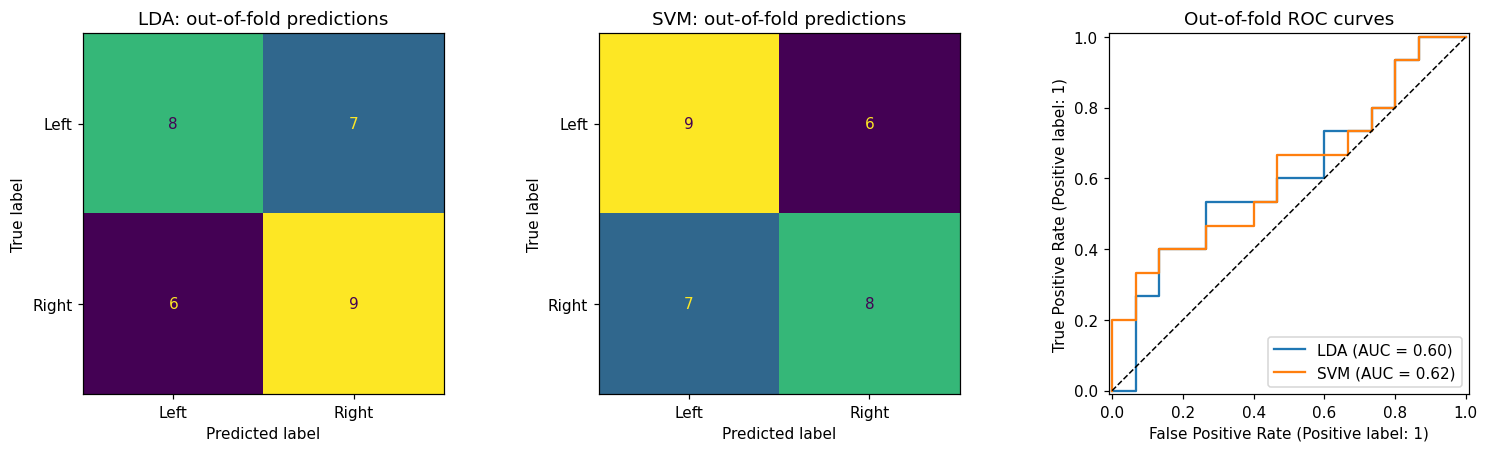

In [8]:
outer = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
splits = list(outer.split(X, y))
param_grid = {"classifier__C": [0.1, 1, 10], "classifier__gamma": ["scale", "auto"]}
oof = {name: {"prediction": np.full(len(y), -1, dtype=int), "probability": np.full(len(y), np.nan)}
       for name in ["LDA", "SVM"]}
fold_rows = []
for fold, (train, test) in enumerate(splits, start=1):
    assert set(train).isdisjoint(test) and len(np.unique(y[test])) == 2
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + fold)
    models = {"LDA": make_pipeline("lda"),
              "SVM": GridSearchCV(make_pipeline("svm"), param_grid, cv=inner,
                                   scoring="accuracy", n_jobs=1, error_score="raise")}
    with threadpool_limits(limits=1):
        for name, model in models.items():
            model.fit(X[train], y[train])
            prediction = model.predict(X[test])
            probability = model.predict_proba(X[test])[:, 1]
            oof[name]["prediction"][test] = prediction
            oof[name]["probability"][test] = probability
            fold_rows.append({"model": name, "fold": fold, "train_n": len(train), "test_n": len(test),
                              "accuracy": accuracy_score(y[test], prediction),
                              "auc": roc_auc_score(y[test], probability),
                              "best_params": str(model.best_params_) if name == "SVM" else "fixed"})
    print(f"Completed outer fold {fold}/10")
write_csv("cv_folds.csv", fold_rows)
cv_metrics = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for idx, name in enumerate(["LDA", "SVM"]):
    prediction, probability = oof[name]["prediction"], oof[name]["probability"]
    assert np.all(prediction >= 0) and np.isfinite(probability).all()
    fold_acc = [row["accuracy"] for row in fold_rows if row["model"] == name]
    cv_metrics[name] = {"accuracy": float(accuracy_score(y, prediction)),
                        "roc_auc": float(roc_auc_score(y, probability)),
                        "fold_accuracy_sd": float(np.std(fold_acc, ddof=1)),
                        "confusion_matrix": confusion_matrix(y, prediction).tolist()}
    print(name, json.dumps(cv_metrics[name]))
    ConfusionMatrixDisplay.from_predictions(y, prediction, display_labels=CLASS_NAMES, ax=axes[idx], colorbar=False)
    axes[idx].set_title(f"{name}: out-of-fold predictions")
    RocCurveDisplay.from_predictions(y, probability, name=name, ax=axes[2])
axes[2].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[2].set_title("Out-of-fold ROC curves")
save_figure(fig, "classifier_oof_metrics")
write_csv("oof_predictions.csv", [{**trial_rows[i], **{f"{name}_{field}": float(oof[name][field][i])
          for name in oof for field in ["prediction", "probability"]}} for i in range(len(y))])

### Additional run-separated check

Random trial folds can share recording conditions. This secondary check holds
out an entire training run at a time. It is not used to change settings, and with
only two runs it is a limited robustness check rather than strong generalization
evidence. SVM hyperparameters are still chosen within the training run.

In [9]:
run_check = []
with threadpool_limits(limits=1):
    for train, test in LeaveOneGroupOut().split(X, y, run_groups):
        for name in ["LDA", "SVM"]:
            model = make_pipeline("lda") if name == "LDA" else GridSearchCV(
                make_pipeline("svm"), param_grid, scoring="accuracy", n_jobs=1,
                cv=StratifiedKFold(3, shuffle=True, random_state=SEED), error_score="raise")
            model.fit(X[train], y[train])
            run_check.append({"model": name, "held_out_run": int(run_groups[test][0]),
                              "accuracy": float(accuracy_score(y[test], model.predict(X[test]))),
                              "auc": float(roc_auc_score(y[test], model.predict_proba(X[test])[:, 1]))})
write_csv("run_separated_check.csv", run_check)
for row in run_check:
    print(row)

{'model': 'LDA', 'held_out_run': 8, 'accuracy': 0.4666666666666667, 'auc': 0.7142857142857142}
{'model': 'SVM', 'held_out_run': 8, 'accuracy': 0.5333333333333333, 'auc': 0.7321428571428572}
{'model': 'LDA', 'held_out_run': 12, 'accuracy': 0.6, 'auc': 0.5714285714285714}
{'model': 'SVM', 'held_out_run': 12, 'accuracy': 0.6, 'auc': 0.5714285714285714}


## 5. Task 4: causal streaming on reserved run 4

The online classifier is a separately fitted CSP + shrinkage LDA pipeline trained
on **500 ms windows**, matching inference. Windows from the training recordings
are never randomly split to claim accuracy; performance is measured on reserved
run 4. Each trial contributes eight non-overlapping training windows.

Replay processes every incoming ten-sample chunk through stateful bandpass and
the fixed ICA projection, updates an 80-sample circular buffer, then computes CSP,
predicts and takes a three-decision majority vote. Timing includes these operations
and starts before chunk extraction. It excludes file loading and plotting.

This is an accelerated replay with a simulated single-worker arrival queue, not
live acquisition. We compute completion lag against a 62.5 ms arrival schedule;
a capacity of one waiting chunk is modelled explicitly to count would-be buffer
overflows. No physical hardware/drop guarantee is claimed. The strict 15 ms
execution target is checked against the **maximum**, not just the average.

Online training windows: (240, 16, 80) from 30 training trials


{
  "chunks": 2000,
  "decisions": 1993,
  "mean_ms": 0.44535445,
  "p95_ms": 0.5648049999999998,
  "max_ms": 1.3954,
  "decision_mean_ms": 0.44657280481685907,
  "chunks_over_15_ms": 0,
  "chunks_over_arrival_period": 0,
  "max_completion_lag_ms": 1.3953999999994267,
  "simulated_queue_drops": 0,
  "all_samples_processed_in_replay": true,
  "strict_latency_pass": true
}


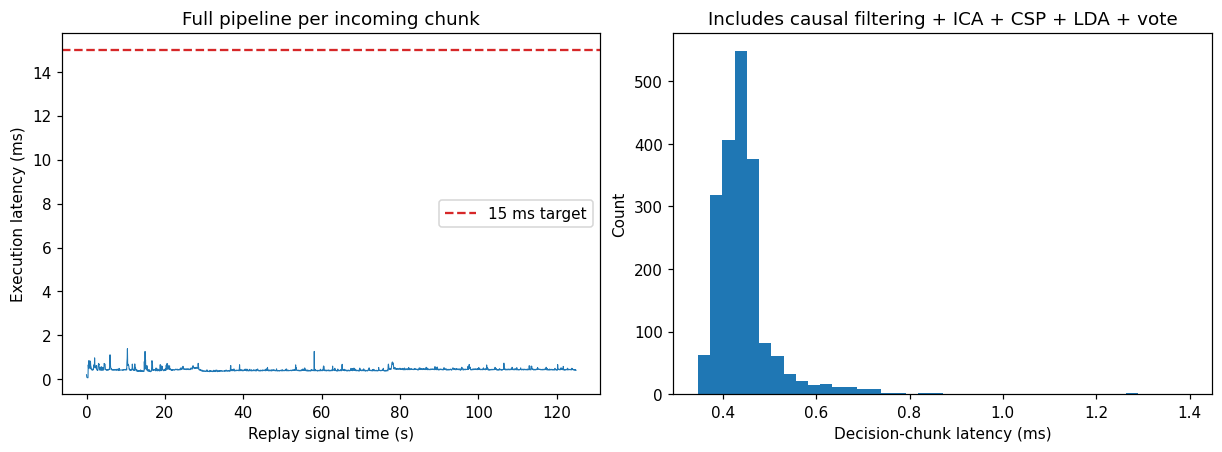

In [10]:
WINDOW, STEP = int(0.5*SFREQ), int(0.0625*SFREQ)
online_x, online_y = [], []
for trial, label in zip(X, y):
    for start in range(0, int(4*SFREQ)-WINDOW+1, WINDOW):
        online_x.append(trial[:, start:start+WINDOW])
        online_y.append(label)
online_x, online_y = np.asarray(online_x), np.asarray(online_y)
online_model = make_pipeline("lda")
with threadpool_limits(limits=1):
    online_model.fit(online_x, online_y)
print("Online training windows:", online_x.shape, "from", len(X), "training trials")

raw_stream = raws[TEST_RUN].get_data()
state = np.zeros((len(SOS), len(CHANNELS), 2))
ring = np.zeros((len(CHANNELS), WINDOW))
write_position = 0
filled = 0
votes = deque(maxlen=3)
chunk_rows = []
online_clean_parts = []
deadline_ms = 1000 * STEP / SFREQ
with threadpool_limits(limits=1):
    for start in range(0, raw_stream.shape[1], STEP):
        tic = perf_counter_ns()
        stop = min(start+STEP, raw_stream.shape[1])
        incoming = raw_stream[:, start:stop]
        filtered, state = sosfilt(SOS, incoming, axis=-1, zi=state)
        processed = ICA_MATRIX @ filtered + ICA_OFFSET
        count = stop-start
        indices = (write_position+np.arange(count)) % WINDOW
        ring[:, indices] = processed
        write_position = (write_position+count) % WINDOW
        filled = min(WINDOW, filled+count)
        raw_prediction = smoothed_prediction = -1
        if filled == WINDOW:
            ordered = np.concatenate([ring[:, write_position:], ring[:, :write_position]], axis=1)
            raw_prediction = int(online_model.predict(ordered[np.newaxis])[0])
            votes.append(raw_prediction)
            # Before three predictions exist, emit the current prediction explicitly.
            smoothed_prediction = int(sum(votes) >= 2) if len(votes) == 3 else raw_prediction
        latency = (perf_counter_ns()-tic)/1e6
        # Diagnostics are recorded outside the timed signal-processing path.
        online_clean_parts.append(processed.copy())
        chunk_rows.append({"start_sample": start, "stop_sample": stop,
                           "latency_ms": latency, "raw_prediction": raw_prediction,
                           "smoothed_prediction": smoothed_prediction, "vote_count": len(votes)})

# Meaningful equivalence check: chunked stateful preprocessing must equal one pass.
online_clean = np.concatenate(online_clean_parts, axis=1)
np.testing.assert_allclose(online_clean, causal_preprocess(raws[TEST_RUN]), rtol=1e-8, atol=1e-13)
assert sum(row["stop_sample"]-row["start_sample"] for row in chunk_rows) == raw_stream.shape[1]
assert all(a["stop_sample"] == b["start_sample"] for a, b in zip(chunk_rows[:-1], chunk_rows[1:]))
decision_rows = [row for row in chunk_rows if row["raw_prediction"] >= 0]
assert len(decision_rows) == (raw_stream.shape[1]-WINDOW)//STEP+1

# Model arrivals at recorded acquisition times, one running + one waiting chunk.
completion_queue = deque()
queue_drops = 0
for row in chunk_rows:
    arrival = row["stop_sample"] / SFREQ * 1000
    while completion_queue and completion_queue[0] <= arrival:
        completion_queue.popleft()
    if len(completion_queue) >= 2:
        queue_drops += 1
        row["simulated_queue_drop"] = True
        row["completion_lag_ms"] = None
    else:
        finish = max(arrival, completion_queue[-1] if completion_queue else arrival) + row["latency_ms"]
        completion_queue.append(finish)
        row["simulated_queue_drop"] = False
        row["completion_lag_ms"] = finish-arrival
latencies = np.array([row["latency_ms"] for row in chunk_rows])
decision_latencies = np.array([row["latency_ms"] for row in decision_rows])
timing = {"chunks": len(chunk_rows), "decisions": len(decision_rows),
          "mean_ms": float(latencies.mean()), "p95_ms": float(np.percentile(latencies, 95)),
          "max_ms": float(latencies.max()), "decision_mean_ms": float(decision_latencies.mean()),
          "chunks_over_15_ms": int((latencies >= 15).sum()),
          "chunks_over_arrival_period": int((latencies > deadline_ms).sum()),
          "max_completion_lag_ms": max(row["completion_lag_ms"] or 0 for row in chunk_rows),
          "simulated_queue_drops": queue_drops,
          "all_samples_processed_in_replay": True, "strict_latency_pass": bool(latencies.max() < 15)}
write_csv("stream_latency.csv", chunk_rows)
print(json.dumps(timing, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(np.arange(len(latencies))*STEP/SFREQ, latencies, linewidth=0.7)
axes[0].axhline(15, color="tab:red", linestyle="--", label="15 ms target")
axes[0].set(xlabel="Replay signal time (s)", ylabel="Execution latency (ms)", title="Full pipeline per incoming chunk")
axes[0].legend()
axes[1].hist(decision_latencies, bins=40)
axes[1].set(xlabel="Decision-chunk latency (ms)", ylabel="Count", title="Includes causal filtering + ICA + CSP + LDA + vote")
save_figure(fig, "stream_latency")

### Held-out streaming accuracy and information transfer rate

The binary model produces labels during rest too, but these are **not meaningful
rest detections** and are excluded from accuracy. Ground-truth annotations are
used only after inference. A scored window must lie entirely within the first
four seconds of an imagery trial; smoothed scores additionally require all three
contributing windows to lie within that same trial.

Overlapping decisions are highly correlated. We report their accuracy descriptively,
then aggregate one majority decision per imagery trial. ITR uses this trial-level
accuracy and the mean cue-to-cue interval including rest; it does **not** treat
the 16 Hz prediction rate as 16 independent commands per second. The Wolpaw formula
assumes independent, equally likely commands and symmetric errors, so it remains
an idealized estimate rather than measured user communication throughput.

{
  "held_out_run": 4,
  "trial_count": 15,
  "overlapping_window_accuracy": 0.7699876998769988,
  "trial_accuracy": 1.0,
  "trial_confusion_matrix": [
    [
      8,
      0
    ],
    [
      0,
      7
    ]
  ],
  "command_period_seconds_including_rest": 8.3,
  "wolpaw_bits_per_trial": 1.0,
  "idealized_ITR_bits_per_min": 7.228915662650602
}


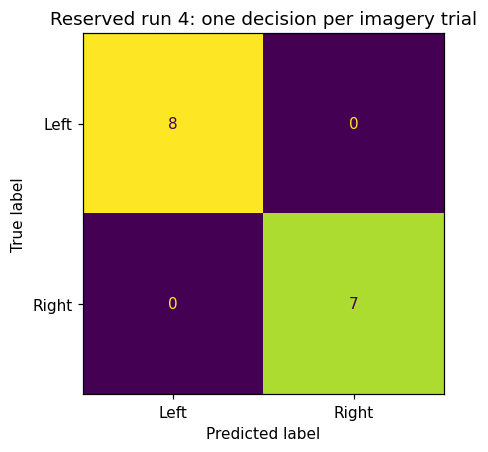

In [11]:
test_trials = []
for onset, duration, description in zip(raws[TEST_RUN].annotations.onset,
                                        raws[TEST_RUN].annotations.duration,
                                        raws[TEST_RUN].annotations.description):
    if description in ["T1", "T2"]:
        first = int(round(onset*SFREQ))
        test_trials.append({"start": first, "stop": first+int(min(4, duration)*SFREQ),
                            "label": 0 if description == "T1" else 1})
window_true, window_pred, trial_true, trial_pred, test_rows = [], [], [], [], []
for number, trial in enumerate(test_trials):
    valid = [row for row in decision_rows if row["stop_sample"]-WINDOW-2*STEP >= trial["start"]
              and row["stop_sample"] <= trial["stop"] and row["vote_count"] == 3]
    if not valid:
        continue
    predictions = np.array([row["smoothed_prediction"] for row in valid])
    # At an exact majority tie, use the latest prediction; no label-dependent tie break.
    vote = int(predictions.mean() > 0.5) if predictions.mean() != 0.5 else int(predictions[-1])
    trial_true.append(trial["label"])
    trial_pred.append(vote)
    window_true.extend([trial["label"]]*len(valid))
    window_pred.extend(predictions.tolist())
    test_rows.append({"trial": number, "start_sample": trial["start"], "true_label": trial["label"],
                      "predicted_label": vote, "scored_windows": len(valid)})
assert len(test_rows) == len(test_trials), "Every held-out imagery trial must be scored."
period_s = float(np.mean(np.diff([trial["start"] for trial in test_trials]))/SFREQ)

def wolpaw_bits(accuracy, classes=2):
    if not 0 <= accuracy <= 1 or classes < 2:
        raise ValueError("Invalid accuracy or class count")
    correct_term = 0 if accuracy == 0 else accuracy*np.log2(accuracy)
    error_term = 0 if accuracy == 1 else (1-accuracy)*np.log2((1-accuracy)/(classes-1))
    return float(np.log2(classes)+correct_term+error_term)

assert np.isclose(wolpaw_bits(0.5), 0) and np.isclose(wolpaw_bits(1), 1)
stream_accuracy = float(accuracy_score(trial_true, trial_pred))
stream_metrics = {"held_out_run": TEST_RUN, "trial_count": len(trial_true),
                  "overlapping_window_accuracy": float(accuracy_score(window_true, window_pred)),
                  "trial_accuracy": stream_accuracy,
                  "trial_confusion_matrix": confusion_matrix(trial_true, trial_pred).tolist(),
                  "command_period_seconds_including_rest": period_s,
                  "wolpaw_bits_per_trial": wolpaw_bits(stream_accuracy),
                  "idealized_ITR_bits_per_min": wolpaw_bits(stream_accuracy)*60/period_s}
print(json.dumps(stream_metrics, indent=2))
if stream_accuracy <= 0.5:
    print("At/below chance: the formula is not evidence of usable BCI communication.")
write_csv("held_out_stream_trials.csv", test_rows)
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ConfusionMatrixDisplay.from_predictions(trial_true, trial_pred, display_labels=CLASS_NAMES, ax=ax, colorbar=False)
ax.set_title("Reserved run 4: one decision per imagery trial")
save_figure(fig, "stream_confusion_matrix")

## 6. Results and submission checks

Performance thresholds are assessment targets, not numbers to manufacture. A correct
pipeline may fail them on this small dataset. Review whether CSP patterns concentrate
around C3/C4 and whether contralateral alpha power decreases; do not assert either
merely because a plot was produced. The 16-channel subset limits spatial resolution.

No true-SNR or clinical efficacy claim is made. Remaining limitations include a single
subject, small test sets, frontal EEG as an ocular proxy, offline calibration,
correlated streaming windows, and simulated rather than physical buffer timing.
The final submission also needs your student ID and a two-page interpretation report.

In this execution, the expected strong contralateral alpha suppression is not
established: check the sign and size of the computed ERD values, including values
near zero. Some CSP maps extend into frontal/parietal regions, so the figures do
not establish exclusive C3/C4 dipoles. Classification and attenuation targets can
remain unmet after methodological errors have been fixed. The held-out streaming
score is for a different, window-trained model and just 15 trials; it does not
replace the ten-fold results or establish reliable performance across subjects.

In [12]:
results = {"versions": versions, "channels": CHANNELS,
           "calibration_runs": CAL_RUNS, "training_runs": TRAIN_RUNS, "reserved_run": TEST_RUN,
           "training_class_counts": np.bincount(y).tolist(), "ica_excluded": ica.exclude,
           "frontal_low_frequency_attenuation_proxy_db": attenuation_db.tolist(),
           "true_snr_improvement_db": None, "cv": cv_metrics, "run_separated_check": run_check,
           "alpha_erd": erd_rows, "timing": timing, "stream": stream_metrics}
with (OUT / "summary.json").open("w", encoding="utf-8") as handle:
    json.dump(results, handle, indent=2)
summary_lines = ["### Computed result summary", "",
                 f"- ICA exclusions: {ica.exclude}; true SNR improvement is not identifiable."]
for name, metrics in cv_metrics.items():
    summary_lines.append(f"- {name}: 10-fold OOF accuracy {metrics['accuracy']:.1%}, AUC {metrics['roc_auc']:.3f}; "
                         f">78.5% target {'met' if metrics['accuracy'] > 0.785 else 'not met'}.")
summary_lines.extend([
    f"- Streaming: held-out trial accuracy {stream_accuracy:.1%}; idealized ITR {stream_metrics['idealized_ITR_bits_per_min']:.2f} bits/min.",
    f"- Maximum full-pipeline latency {timing['max_ms']:.2f} ms; <15 ms target {'met' if timing['strict_latency_pass'] else 'not met'}.",
    f"- Simulated queue drops: {queue_drops}; all replay samples processed.",
    "- Required plots and machine-readable benchmark logs are saved under results/.",
    "- For submission: explain the actual results, the SNR limitation, and the additional calibration/training runs in the two-page report."
])
display(Markdown("\n".join(summary_lines)))
print("Output directory:", OUT.resolve())

### Computed result summary

- ICA exclusions: [1]; true SNR improvement is not identifiable.
- LDA: 10-fold OOF accuracy 56.7%, AUC 0.604; >78.5% target not met.
- SVM: 10-fold OOF accuracy 56.7%, AUC 0.618; >78.5% target not met.
- Streaming: held-out trial accuracy 100.0%; idealized ITR 7.23 bits/min.
- Maximum full-pipeline latency 1.40 ms; <15 ms target met.
- Simulated queue drops: 0; all replay samples processed.
- Required plots and machine-readable benchmark logs are saved under results/.
- For submission: explain the actual results, the SNR limitation, and the additional calibration/training runs in the two-page report.

Output directory: D:\Github\motor-imagery-bci-signal-processing\assignment\results
